# QuantCore · 실제 미국 주식 백테스트

**AAPL·MSFT·NVDA·TSLA·SPY의 실제 Alpaca IEX 과거 시세를 사용한 모의 매매입니다. 실계좌의 실현 수익률이 아닙니다.**

- 1분봉을 XNYS 정규장으로 필터링하고 일봉으로 집계합니다. 휴장·서머타임·조기 폐장을 반영합니다.
- 원시 가격으로 거래하고, 분할은 수량/시그널 기준에 반영합니다. 배당 권리는 ex-date에 발생하며 현금은 payable date 다음 거래일부터 사용한다고 가정합니다.
- Momentum·Mean Reversion과 95% 비중 유지 BuyHold를 같은 조건으로 비교합니다. 매도·매수 가격은 다음 정규장 첫 관측 IEX 1분봉의 시가이며 실제 주문 체결을 보장하지 않습니다.
- **커널: QuantCore (Python 3.12)** 또는 준비된 상위 `.venv312`. **Run All**을 실행하세요. API/Docker 없이 동결된 로컬 자료를 읽으며 주문·재수집은 하지 않습니다.
- 실제 자료가 없으면 명시적으로 중단합니다. 합성 자료로 대체하지 않습니다. `scripts/collect_real_equities.py --env-file /authorized/path/.env`로 수집 후 실행합니다.

원시 시세·API 응답·체결가격 CSV는 로컬 데이터/결과 폴더에 보관합니다. 공개용 기본 출력에는 원시 가격 차트를 표시하지 않습니다.


In [1]:
import hashlib
import importlib.util
import json
import os
import sys
from pathlib import Path

if sys.version_info < (3, 12):
    raise RuntimeError('Python 3.12 이상 커널을 선택하세요.')
candidates = []
for parent in (Path.cwd(), *Path.cwd().parents):
    candidates.extend([parent, parent / 'jane' / 'quant'])
REPO_DIR = next((p for p in candidates if (p / 'quantcore/backtesting/engine.py').is_file()), None)
if REPO_DIR is None:
    raise RuntimeError('QuantCore 프로젝트 또는 notebooks 폴더에서 실행하세요.')
required = ['numpy', 'pandas', 'matplotlib', 'IPython', 'ipywidgets', 'sqlalchemy', 'pyarrow', 'jinja2', 'dotenv', 'exchange_calendars']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    project_python = REPO_DIR / '.venv/bin/python'
    raise RuntimeError(
        f"필요한 패키지가 없습니다: {missing}\n"
        f"현재 커널: {sys.executable}\n"
        f"권장 커널: QuantCore (Python 3.12)\n"
        f"권장 Python 경로: {project_python}\n"
        "오른쪽 위 커널 선택 → 다른 커널 선택 → Python 환경에서 위 경로를 선택하세요.\n"
        "목록에 없으면 프로젝트 터미널에서 make notebook-setup을 실행하고 창을 다시 여세요.\n"
        "커널을 바꾼 후 Restart Kernel → Run All을 실행하세요."
    )
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
os.environ.setdefault('MPLCONFIGDIR', str(REPO_DIR / 'artifacts' / 'matplotlib'))

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import clear_output, display
from matplotlib.ticker import PercentFormatter

import quantcore
from quantcore.backtesting.engine import ExecutionConfig, simulate
from quantcore.data.providers.alpaca import load_snapshot
from quantcore.research.real_equities import latest_snapshot, run_actual
from quantcore.research.service import json_safe
from quantcore.strategies.base import STRATEGIES

if Path(quantcore.__file__).resolve().parent != REPO_DIR / 'quantcore':
    raise RuntimeError('다른 quantcore 모듈이 이미 로드되어 있습니다. 커널을 재시작하세요.')
%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4.5), 'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})
pd.set_option('display.max_columns', 24)
print('Project:', REPO_DIR)
print('Python:', sys.executable)
print('Data: ACTUAL HISTORICAL IEX / USD / simulation only')


Project: /Users/kanghyeon/Desktop/Project/jane/quant
Python: /Users/kanghyeon/Desktop/Project/jane/quant/.venv/bin/python
Data: ACTUAL HISTORICAL IEX / USD / simulation only


## 1. 같은 전략·거래 조건

기본 선택은 AAPL / Momentum입니다. 60봉 평균 돌파 Momentum, 20봉 z-score 회귀 Mean Reversion, 95% 목표 비중 BuyHold를 그대로 사용합니다.
평가는 공통 마지막 252거래일, 초기자금 $100,000, 수수료 1bp·슬리피지 2bp·전체 spread 2bp(편도 절반)·impact 5bp×√참여율입니다.
이전 정규장 IEX 거래량의 1%를 유동성 한도로 사용합니다. 현금·정수 수량·배당 미수금을 별도로 추적하며 공매도/차입/실주문은 하지 않습니다.
신호는 이전 정규장 종가 이후, 체결은 다음 정규장 첫 관측 1분 시가로 모델링합니다. 통합시장 SIP나 거래소 개장 경매 가격을 재현한 결과가 아닙니다.


In [2]:
SYMBOL = 'AAPL'
STRATEGY = 'momentum'  # momentum / mean_reversion / buy_hold
CONFIG = ExecutionConfig(
    initial_cash=100_000,
    evaluation_bars=252,
    commission_bps=1,
    slippage_bps=2,
    spread_bps=2,
    impact_bps=5,
    max_participation=.01,
)
EXPORT_RESULTS = True  # 로컬 artifacts/notebook_backtest/에 CSV·JSON·PNG 저장
display(pd.Series(CONFIG.model_dump(), name='assumption').to_frame())

SHOW_RAW_DATA = False  # True: 개인 로컬 분석에서만 원시 시세/체결가격 표시


,assumption
initial_cash,100000.00
commission_bps,1.00
slippage_bps,2.00
spread_bps,2.00
impact_bps,5.00
max_participation,0.01
max_weight,1.00
evaluation_bars,252.00


## 2. 실제 자료 동결본 확인

시세 파일·기업행사·거래일의 SHA-256을 검증합니다. 데이터 수집 시각과 과거 가격 기준일을 구분합니다.
아래 범위는 학습 시점의 실시간 기록이 아니라 지금 수집한 과거 보관본입니다. 과거 정정 이력과 당시 실제 지연은 확보하지 못했습니다.


In [3]:
SNAPSHOT_DIR = latest_snapshot(REPO_DIR)
market, ACTIONS, manifest = load_snapshot(SNAPSHOT_DIR)
input_hash = manifest['hashes']['prices.parquet']
input_origin = 'frozen actual Alpaca IEX 1-minute regular-session aggregate'
FRAMES = {symbol: group.set_index('timestamp').sort_index() for symbol, group in market.groupby('symbol')}
assert set(market['mode']) == {'historical'}
if SYMBOL not in FRAMES or STRATEGY not in STRATEGIES:
    raise ValueError('종목 또는 전략을 확인하세요.')
display(market.groupby('symbol').agg(sessions=('close', 'size'), start=('timestamp', 'min'), end=('timestamp', 'max')))
display(pd.Series({key: manifest[key] for key in ['collected_at','start','end','minute_rows_downloaded','regular_minute_rows','daily_rows','actions_counts']}, name='actual data').to_frame())
print('Input SHA-256:', input_hash)
print('Data: historical; source:', manifest['source'], '| calendar:', manifest['calendar'])


,sessions,start,end
symbol,,,
AAPL,354,2025-07-01 20:00:00+00:00,2026-11-24 21:00:00+00:00
MSFT,354,2025-07-01 20:00:00+00:00,2026-11-24 21:00:00+00:00
NVDA,354,2025-07-01 20:00:00+00:00,2026-11-24 21:00:00+00:00
SPY,354,2025-07-01 20:00:00+00:00,2026-11-24 21:00:00+00:00
TSLA,354,2025-07-01 20:00:00+00:00,2026-11-24 21:00:00+00:00


,actual data
collected_at,2026-11-25T01:40:39.039381+00:00
start,2025-07-01
end,2026-11-24
minute_rows_downloaded,698235
regular_minute_rows,683312
daily_rows,1770
actions_counts,{'cash_dividends': 25}


Input SHA-256: 6585746b9e19f8adcc07e3a4573549c0a312d3875593ef614581445c78a277cd
Data: historical; source: alpaca-iex-regular-1min | calendar: XNYS


## 3. 실제 종목 · 비용 차감 성과 비교

15개 비교는 각 종목별 모의 계좌입니다. 5개 종목의 수익률을 합산한 포트폴리오 성과가 아닙니다.
95% BuyHold는 같은 종목의 목표 비중 유지 벤치마크입니다. 전략을 결과에 맞춰 튜닝하거나 좋은 종목만 제외·선택하지 않습니다.


Actual-input validation: 15 comparisons passed cash/NAV/time/future-data audits


,symbol,strategy,total_return,gross_total_return,benchmark_total_return,sharpe,max_drawdown,fills,total_cost
0,AAPL,momentum,11.07%,11.78%,29.39%,0.612,-13.05%,57,$637.62
1,AAPL,mean_reversion,4.22%,4.60%,29.39%,0.390,-11.29%,23,$379.81
2,AAPL,buy_hold,29.39%,29.45%,29.39%,1.212,-13.10%,62,$45.77
3,MSFT,momentum,-0.11%,0.06%,5.28%,0.083,-12.89%,23,$236.08
4,MSFT,mean_reversion,3.71%,4.47%,5.28%,0.288,-16.21%,30,$770.18
5,MSFT,buy_hold,5.28%,5.37%,5.28%,0.318,-26.68%,49,$46.77
6,NVDA,momentum,-15.43%,-14.50%,-12.17%,-0.532,-23.10%,65,$984.23
7,NVDA,mean_reversion,-2.10%,-1.37%,-12.17%,0.142,-41.61%,61,$859.62
8,NVDA,buy_hold,-12.17%,-12.12%,-12.17%,-0.030,-45.61%,110,$48.18
9,SPY,momentum,4.07%,5.01%,9.13%,0.473,-7.51%,32,$936.59


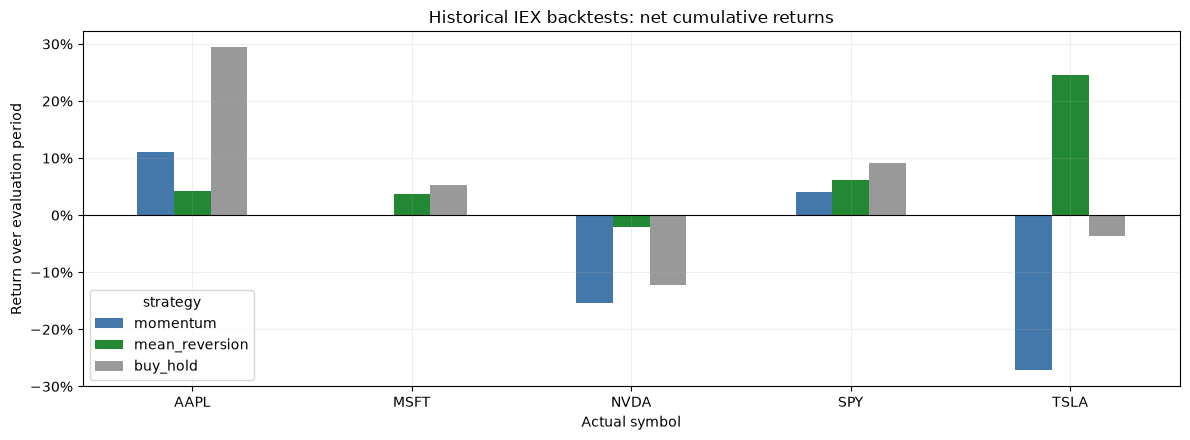

In [4]:
FRAMES, ACTIONS, RESULTS, SUMMARY, EXPERIMENT, VALIDATION = run_actual(SNAPSHOT_DIR, CONFIG)
print('Actual-input validation:', len(VALIDATION), 'comparisons passed cash/NAV/time/future-data audits')
return_columns = ['total_return', 'gross_total_return', 'benchmark_total_return', 'max_drawdown', 'win_rate']
formats = {column: '{:.2%}' for column in return_columns}
formats.update(sharpe='{:.3f}', total_cost='${:,.2f}', turnover='{:.3f}')
display(SUMMARY[['symbol', 'strategy', 'total_return', 'gross_total_return', 'benchmark_total_return',
                 'sharpe', 'max_drawdown', 'fills', 'total_cost']].style.format(formats, na_rep='—'))
NET = SUMMARY.pivot(index='symbol', columns='strategy', values='total_return')
ax = NET[['momentum', 'mean_reversion', 'buy_hold']].plot.bar(color=['#4477aa', '#228833', '#999999'])
ax.axhline(0, color='black', linewidth=.8)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Historical IEX backtests: net cumulative returns', ylabel='Return over evaluation period', xlabel='Actual symbol')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. 선택 종목의 수익곡선과 낙폭

실선은 비용 차감 후, 점선은 비용을 0으로 놓고 다시 실행한 결과입니다. **비용 전 성과는 실제 투자 성과 추정치가 아닙니다.**
평가 시작 직전의 초기 자금을 곡선에 포함해 첫날부터의 손실과 낙폭을 표시합니다.

배당은 미수금과 지급 현금을 포함한 경제적 계좌 가치로 반영합니다. IEX 과거 자료 기반이며 실제 실현 수익이 아닙니다.


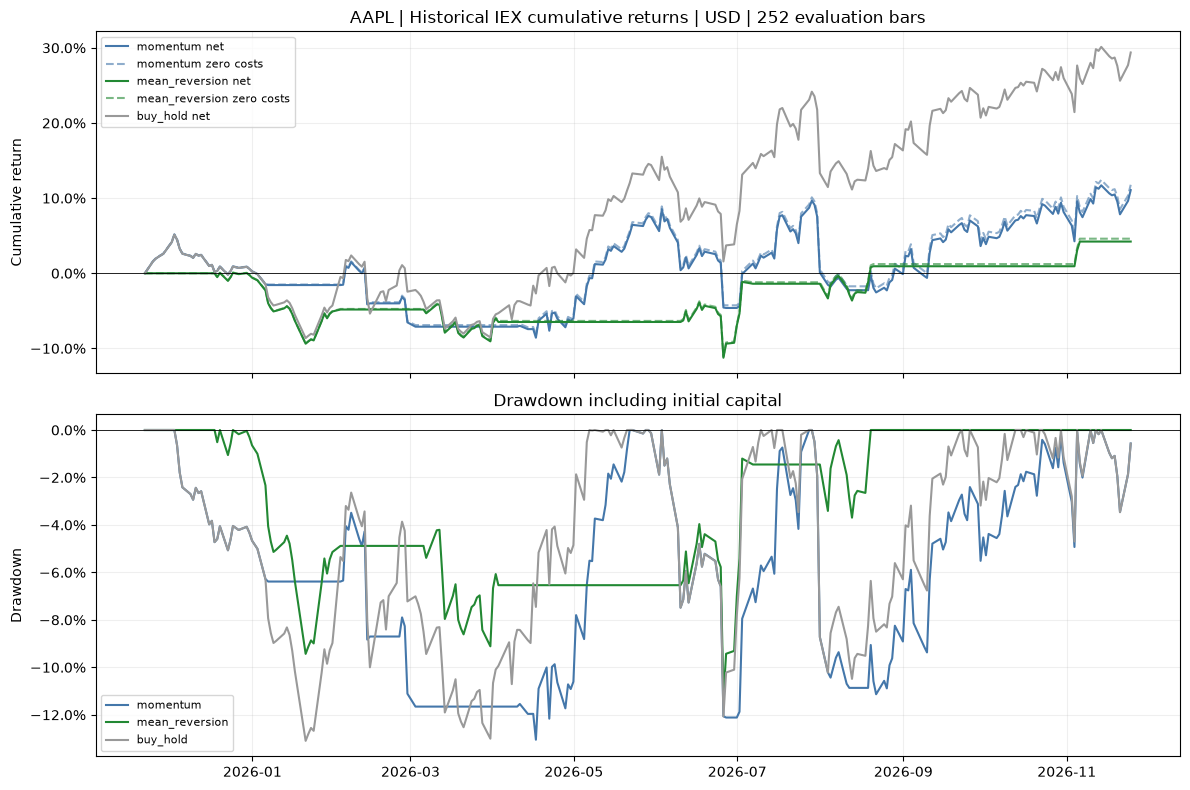

In [5]:
def equity_frame(symbol, result):
    curve = pd.DataFrame(result['curve'])
    curve['timestamp'] = pd.to_datetime(curve.timestamp, utc=True)
    curve = curve.set_index('timestamp')
    frame = FRAMES[symbol]
    initial_at = frame.index[frame.index.get_loc(curve.index[0]) - 1]
    initial = pd.DataFrame({'equity': [CONFIG.initial_cash], 'benchmark_equity': [CONFIG.initial_cash]},
                           index=pd.DatetimeIndex([initial_at], name='timestamp'))
    return pd.concat([initial, curve]).sort_index()

COLORS = {'momentum': '#4477aa', 'mean_reversion': '#228833', 'buy_hold': '#999999'}
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ZERO_COST = CONFIG.model_copy(update=dict(commission_bps=0, slippage_bps=0, spread_bps=0, impact_bps=0))
for name, color in COLORS.items():
    result = RESULTS[SYMBOL, name]
    curve = equity_frame(SYMBOL, result)
    net = curve.equity / CONFIG.initial_cash - 1
    axes[0].plot(curve.index, net, label=name+' net', color=color)
    drawdown = curve.equity / curve.equity.cummax() - 1
    axes[1].plot(curve.index, drawdown, label=name, color=color)
    assert np.isclose(drawdown.min(), result['metrics']['max_drawdown'], atol=1e-12)
    if name != 'buy_hold':
        gross_result = simulate(FRAMES[SYMBOL], STRATEGIES[name](), ZERO_COST, ACTIONS[SYMBOL])
        gross_curve = equity_frame(SYMBOL, gross_result)
        axes[0].plot(gross_curve.index, gross_curve.equity / CONFIG.initial_cash - 1,
                     linestyle='--', alpha=.6, color=color, label=name+' zero costs')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.axhline(0, color='black', linewidth=.6)
    ax.legend(loc='best', fontsize=8)
axes[0].set(title=f'{SYMBOL} | Historical IEX cumulative returns | USD | {CONFIG.evaluation_bars} evaluation bars', ylabel='Cumulative return')
axes[1].set(title='Drawdown including initial capital', ylabel='Drawdown')
plt.tight_layout()
plt.show()


## 5. 선택 종목 상세와 체결 기록

평가액에는 배당 미수금이 포함됩니다. 미수금은 현금 지급 전 매수 자금으로 쓸 수 없습니다.
기본 그래프는 자산 곡선과 낙폭입니다. `SHOW_RAW_DATA=True`일 때만 개인 로컬 분석용 원시 가격/체결가격을 표시합니다.
승률·Profit Factor는 청산 매도 체결 기준입니다. 수익률·평가액·체결 수를 서로 다른 단위로 해석하세요.


AAPL / momentum | ACTUAL HISTORICAL IEX / USD | 2025-11-24 → 2026-11-24


,value
metric,
total_return,11.07%
cagr,11.07%
annualized_volatility,20.66%
sharpe,0.612
sortino,0.862
max_drawdown,-13.05%
drawdown_duration_bars,116
calmar,0.849
fills,57


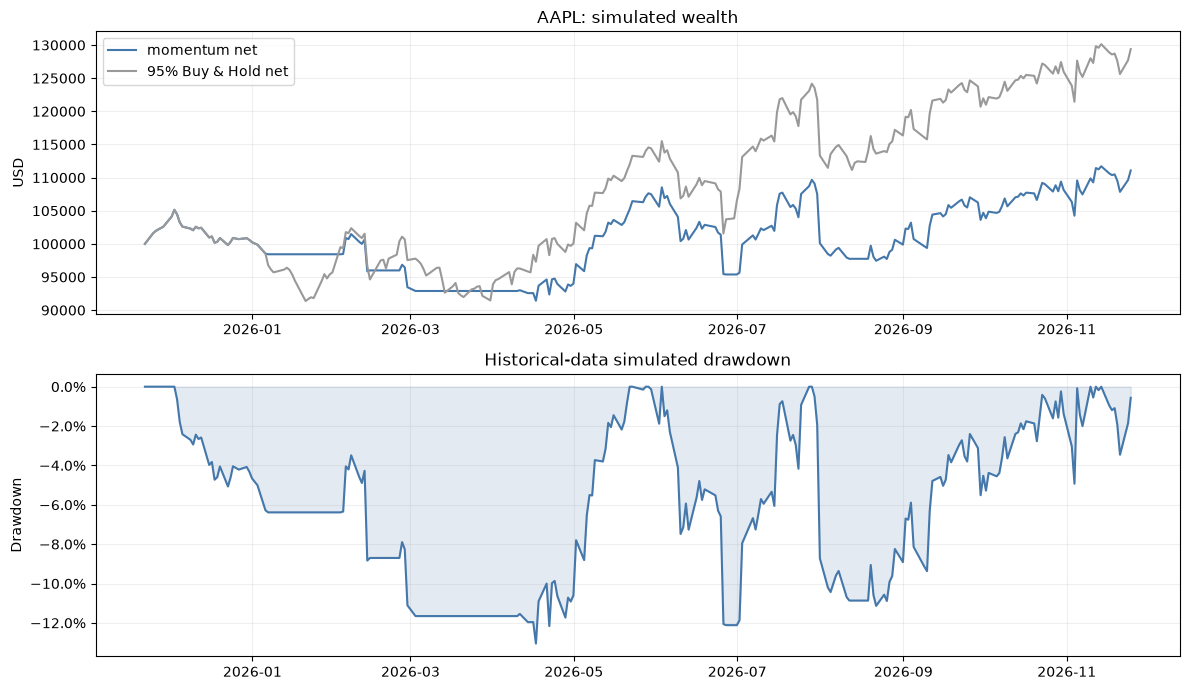

,signal_at,timestamp,side,quantity,commission,total_cost,partial_fill
32,2026-07-22T20:01:00+00:00,2026-07-23T13:30:00+00:00,buy,1,0.0322,0.128874,False
33,2026-07-24T20:01:00+00:00,2026-07-27T13:30:00+00:00,sell,1,0.0336,0.134445,False
34,2026-07-30T20:01:00+00:00,2026-07-31T13:30:00+00:00,buy,2,0.0610,0.244140,False
35,2026-07-31T20:01:00+00:00,2026-08-03T13:30:00+00:00,sell,1,0.0310,0.124000,False
36,2026-08-03T20:01:00+00:00,2026-08-04T13:30:00+00:00,sell,307,9.2910,37.624991,False
37,2026-08-04T20:01:00+00:00,2026-08-05T13:30:00+00:00,buy,301,9.3116,37.790910,False
38,2026-08-10T20:01:00+00:00,2026-08-11T13:30:00+00:00,sell,301,9.2579,37.679454,False
39,2026-08-18T20:01:00+00:00,2026-08-19T13:30:00+00:00,buy,299,9.2762,37.743211,False
40,2026-08-19T20:01:00+00:00,2026-08-20T13:30:00+00:00,sell,1,0.0317,0.127060,False
41,2026-08-20T20:01:00+00:00,2026-08-21T13:30:00+00:00,buy,1,0.0312,0.124772,False


In [6]:
def show_detail(symbol, name):
    result = RESULTS[symbol, name]
    print(f'{symbol} / {name} | ACTUAL HISTORICAL IEX / USD | {result["period"]["start"][:10]} → {result["period"]["end"][:10]}')
    percent_metrics = {'total_return', 'cagr', 'annualized_volatility', 'max_drawdown', 'win_rate',
                       'alpha', 'tracking_error', 'benchmark_relative_return'}
    metric_rows = []
    for key, value in result['metrics'].items():
        if value is None:
            formatted = '—'
        elif key in percent_metrics:
            formatted = f'{value:.2%}'
        elif key == 'total_cost':
            formatted = f'${value:,.2f}'
        elif key in {'fills', 'closed_fills', 'drawdown_duration_bars'}:
            formatted = str(int(value))
        else:
            formatted = f'{value:,.3f}'
        metric_rows.append({'metric': key, 'value': formatted})
    display(pd.DataFrame(metric_rows).set_index('metric'))
    curve = equity_frame(symbol, result)
    fig, axes = plt.subplots(2, 1, figsize=(12, 7))
    axes[0].plot(curve.index, curve.equity, label=name+' net', color=COLORS[name])
    axes[0].plot(curve.index, curve.benchmark_equity, label='95% Buy & Hold net', color='#999999')
    axes[0].set(title=f'{symbol}: simulated wealth', ylabel='USD')
    axes[0].legend()
    fills = pd.DataFrame(result['fills'])
    if not fills.empty:
        assert (pd.to_datetime(fills.signal_at, utc=True) < pd.to_datetime(fills.timestamp, utc=True)).all()
    if SHOW_RAW_DATA:
        price = FRAMES[symbol].loc[curve.index.min():, 'close']
        axes[1].plot(price.index, price, color='#555555', linewidth=1)
        if not fills.empty:
            for side, marker, color in [('buy', '^', '#228833'), ('sell', 'v', '#cc3311')]:
                chosen = fills[fills.side == side]
                axes[1].scatter(pd.to_datetime(chosen.timestamp, utc=True), chosen.price, marker=marker, color=color, label=side, s=28)
        axes[1].set(title='Private view: first observed regular-session minute fills', ylabel='USD / share')
    else:
        drawdown = curve.equity / curve.equity.cummax() - 1
        axes[1].plot(curve.index, drawdown, color=COLORS[name])
        axes[1].fill_between(curve.index, drawdown, 0, alpha=.15, color=COLORS[name])
        axes[1].yaxis.set_major_formatter(PercentFormatter(1))
        axes[1].set(title='Historical-data simulated drawdown', ylabel='Drawdown')
    plt.tight_layout()
    plt.show()
    if fills.empty:
        print('이 조건에서는 체결이 없습니다.')
    else:
        columns = ['signal_at', 'timestamp', 'side', 'quantity', 'commission', 'total_cost', 'partial_fill']
        if SHOW_RAW_DATA:
            columns += ['price', 'cash_after', 'inventory_after', 'realized_pnl']
        display(fills[columns].tail(25))
    return result

SELECTED = show_detail(SYMBOL, STRATEGY)


## 6. 월별 수익률 · 비용 민감도

월별 수익률은 일별 수익률의 복리입니다. 비용 민감도는 수수료·슬리피지·spread·impact 계수를 함께 배수 적용해 재실행합니다.
계수 변경에 따라 보유 수량과 체결이 바뀔 수 있으므로 결과 차이를 비용 항목의 단순 합으로 해석하지 않습니다.


,equity,benchmark_equity
timestamp,,
2025-11,2.59%,2.59%
2025-12,-2.29%,-2.29%
2026-01,-1.81%,-4.53%
2026-02,-5.05%,1.93%
2026-03,-0.61%,-3.71%
2026-04,1.19%,6.50%
2026-05,14.36%,14.35%
2026-06,-11.26%,-6.92%
2026-07,4.94%,6.42%


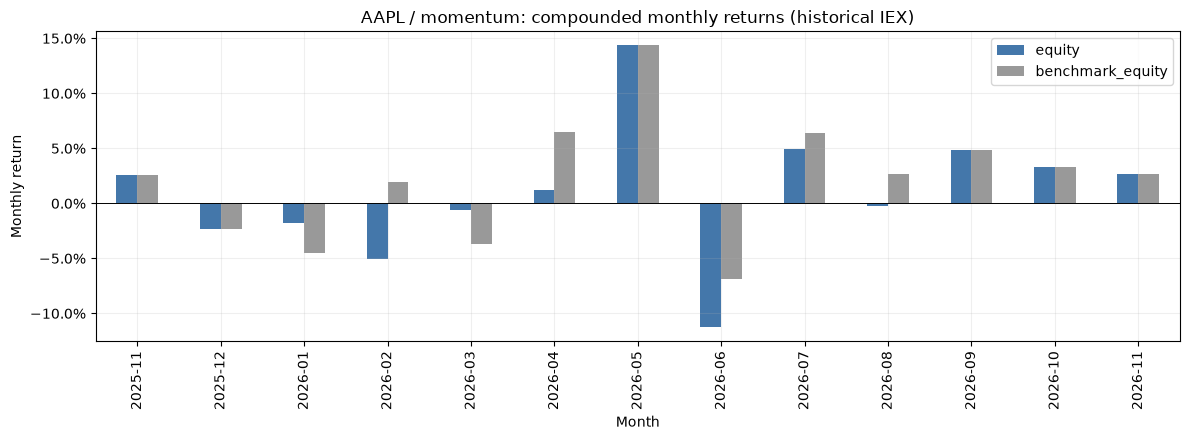

,cost_multiplier,total_return,max_drawdown,total_cost,fills
0,0.000000,11.78%,-12.78%,$0.00,44
1,0.500000,11.44%,-12.91%,$319.53,61
2,1.000000,11.07%,-13.05%,$637.62,57
3,2.000000,10.32%,-13.32%,"$1,269.33",49


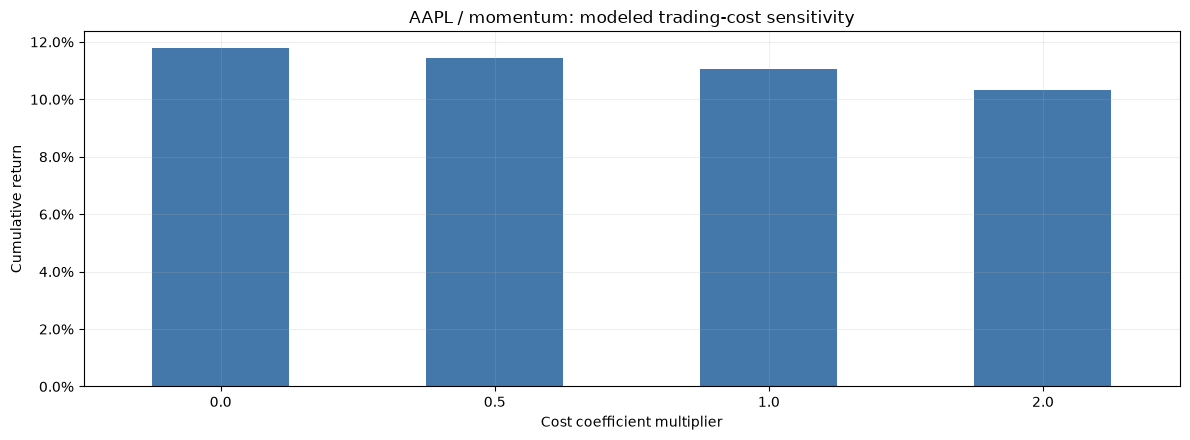

In [7]:
selected_curve = equity_frame(SYMBOL, SELECTED)
daily = selected_curve[['equity', 'benchmark_equity']].pct_change().iloc[1:]
monthly = (1 + daily).resample('MS').prod() - 1
monthly.index = monthly.index.strftime('%Y-%m')
display(monthly.style.format('{:.2%}'))
ax = monthly.plot.bar(color=[COLORS[STRATEGY], '#999999'])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title=f'{SYMBOL} / {STRATEGY}: compounded monthly returns (historical IEX)', ylabel='Monthly return', xlabel='Month')
ax.axhline(0, color='black', linewidth=.7)
plt.tight_layout()
plt.show()

cost_rows = []
for multiplier in (0., .5, 1., 2.):
    scaled = CONFIG.model_copy(update={name: getattr(CONFIG, name)*multiplier for name in
                                      ('commission_bps', 'slippage_bps', 'spread_bps', 'impact_bps')})
    result = simulate(FRAMES[SYMBOL], STRATEGIES[STRATEGY](), scaled, ACTIONS[SYMBOL])
    cost_rows.append({'cost_multiplier': multiplier, **result['metrics']})
COST_SENSITIVITY = pd.DataFrame(cost_rows)
display(COST_SENSITIVITY[['cost_multiplier', 'total_return', 'max_drawdown', 'total_cost', 'fills']]
        .style.format({'total_return': '{:.2%}', 'max_drawdown': '{:.2%}', 'total_cost': '${:,.2f}'}))
ax = COST_SENSITIVITY.plot.bar(x='cost_multiplier', y='total_return', legend=False, color='#4477aa')
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title=f'{SYMBOL} / {STRATEGY}: modeled trading-cost sensitivity', ylabel='Cumulative return', xlabel='Cost coefficient multiplier')
ax.axhline(0, color='black', linewidth=.7)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 7. 실제 실험과 대조 · 로컬 파일 저장

같은 실제 입력 해시와 기본 설정이면 저장된 15개 비교 결과와 일치하는지 확인합니다.
원시 입력과 체결 CSV는 로컬에만 보관하며, 공개용 노트북의 기본 출력은 요약 성과와 직접 계산한 곡선입니다.


In [8]:
reference_path = REPO_DIR / 'docs/real_equity_results.json'
reference_status = 'not compared: input or configuration differs'
if reference_path.exists():
    reference = json.loads(reference_path.read_text())
    if reference['metadata']['snapshot_hashes'] == manifest['hashes'] and reference['metadata']['config'] == CONFIG.model_dump() and reference['metadata'].get('code_sha256') == EXPERIMENT['code_sha256']:
        errors = [abs(RESULTS[row['symbol'], row['strategy']]['metrics']['total_return'] - row['total_return']) for row in reference['results']]
        assert len(errors) == 15 and max(errors) < 1e-10
        reference_status = f'matched 15 saved actual-data results; max return difference={max(errors):.3e}'
print(reference_status)
display(VALIDATION)
if EXPORT_RESULTS:
    run_id = hashlib.sha256(json.dumps({'input': manifest['hashes'], 'config': CONFIG.model_dump(), 'code': EXPERIMENT['code_sha256']}, sort_keys=True).encode()).hexdigest()[:12]
    OUTPUT_DIR = REPO_DIR / 'artifacts/notebook_real_equities' / run_id
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    SUMMARY.to_csv(OUTPUT_DIR / 'metrics.csv', index=False)
    COST_SENSITIVITY.to_csv(OUTPUT_DIR / 'cost_sensitivity.csv', index=False)
    monthly.to_csv(OUTPUT_DIR / 'selected_monthly_returns.csv')
    pd.concat([pd.DataFrame(r['curve']).assign(symbol=s, strategy=n) for (s,n),r in RESULTS.items()]).to_csv(OUTPUT_DIR / 'curves.csv', index=False)
    trades = [pd.DataFrame(r['fills']).assign(symbol=s, strategy=n) for (s,n),r in RESULTS.items() if r['fills']]
    if trades:
        pd.concat(trades, ignore_index=True).to_csv(OUTPUT_DIR / 'fills.csv', index=False)
    (OUTPUT_DIR / 'experiment.json').write_text(json.dumps(json_safe(EXPERIMENT), indent=2)+chr(10))
    print('Private local outputs:', OUTPUT_DIR)


matched 15 saved actual-data results; max return difference=0.000e+00


,symbol,strategy,mode,period,sessions,signal_before_execution,cash_inventory_nav_reconciled,future_mutation_invariant
0,AAPL,momentum,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
1,AAPL,mean_reversion,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
2,AAPL,buy_hold,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
3,MSFT,momentum,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
4,MSFT,mean_reversion,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
5,MSFT,buy_hold,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
6,NVDA,momentum,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
7,NVDA,mean_reversion,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
8,NVDA,buy_hold,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True
9,SPY,momentum,historical,"{'start': '2025-11-24T21:00:00+00:00', 'end': ...",252,True,True,True


Private local outputs: /Users/kanghyeon/Desktop/Project/jane/quant/artifacts/notebook_real_equities/40d2558eb9d4


## 8. 실제 종목을 선택해서 보기

종목과 전략을 바꿔 **상세 결과 보기**를 누르면 결과가 갱신됩니다.
실제 1분봉과 배당 정보를 쓴 과거 모의 매매이며, 미래 성과를 보장하거나 실계좌 수익을 보고하는 기능이 아닙니다.
일부 종목·전략의 손실 및 BuyHold보다 낮은 성과도 그대로 포함했습니다. 개장 시가 체결·영향·수수료·배당 현금 시각은 명시된 모델 가정입니다.


In [9]:
asset_picker = widgets.Dropdown(options=sorted(FRAMES), value=SYMBOL, description='종목:')
strategy_picker = widgets.Dropdown(options=list(STRATEGIES), value=STRATEGY, description='전략:')
detail_button = widgets.Button(description='상세 결과 보기', button_style='info')
detail_output = widgets.Output()

def refresh_detail(_):
    with detail_output:
        clear_output(wait=True)
        show_detail(asset_picker.value, strategy_picker.value)

detail_button.on_click(refresh_detail)
display(widgets.HBox([asset_picker, strategy_picker, detail_button]), detail_output)


Output()